# Постановка задачи и описание данных

**Источник данных:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams2011).

**Бизнес-цель:** Прогнозирование почасового потребления электроэнергии для оптимизации нагрузки на электросети, снижения затрат на закупку энергии и выявления аномалий.

**Задача:** Регрессия временного ряда (прогнозирование числового значения).

**Структура данных:**

- Каждый столбец соответствует одному клиенту.
- Значения указаны в киловаттах за каждые 15 минут.  Чтобы перевести значения в киловатт-часы, их нужно разделить на 4.  
- В наборе данных нет пропущенных значений.
- Некоторые клиенты были созданы после 2011 года. В этих случаях потребление считалось нулевым.
- Все временные метки указаны в португальских часах. Однако во всех днях по 96 измерений (24*4).
- Каждый год в день перехода на зимнее время в марте (когда в сутках всего 23 часа) значения с 01:00 до 02:00 равны нулю для всех точек.
- Каждый год в день перехода на зимнее время в октябре (когда в сутках 25 часов) значения с 01:00 до 02:00 суммируют потребление за два часа.

---

Набор данных был сохранен в формате txt с использованием формата csv и разделителя-точки с запятой (;).
- В первом столбце дата и время представлены в виде строки в следующем формате: 'гггг-мм-дд чч:мм:сс'
- В остальных столбцах представлены значения с плавающей запятой, отражающие потребление в кВт


# Библиотеки

In [ ]:
!pip install shap -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, make_scorer

import shap

from scipy.stats import ks_2samp

import warnings
warnings.filterwarnings('ignore')

# Функции

In [ ]:
def train_model(X, y, model_grid, test_size):
    '''
    Принимает на вход отдельно признаки и цп,
    сетку параметров модели и пропорции разбиения на трейн и тест
    с учётом хронологии.

    ДАННЫЕ ДОЛЖНЫ БЫТЬ ОТСОРТИРОВАНЫ ОТ СТАРЫХ К НОВЫМ!!!

    Реализована кросс-валидация (TimeSeriesSplit) и подбор
    гиперпараметров по сетке внутри GridSearchCV. Сравниваются метрики
    на train (CV) и test. Scaler (если есть) обучается только на train-e.

    Для каждой модели сохраняются:
        model, RMSE, MAPE                       — метрики на тесте
        cv_mean_rmse, cv_std_rmse               — среднее ± std по фолдам CV
        cv_mean_mape, cv_std_mape               — то же для MAPE
        cv_fold_rmse, cv_fold_mape              — значения по каждому фолду
        cv_coef_rmse                            — std/mean (коэф. вариации)
        best_params                             — лучшие гиперпараметры
    '''
    result = {}
    try:
        model_name = type(model_grid['model']['regressor']).__name__
    except Exception:
        model_name = type(model_grid['model']).__name__

    # разбиение данных с сохранением хронологии ---
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    # кросс-валидация + подбор гиперпараметров
    search = GridSearchCV(
        estimator=model_grid['model'],
        param_grid=model_grid['params'],
        scoring=scoring,
        refit='rmse',
        cv=tscv,
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    best_idx   = search.best_index_
    cv         = search.cv_results_

    # CV: mean ± std по фолдам
    # В cv_results_ метрики хранятся со знаком минус (neg_*),
    # std при этом положительный — просто берём abs для mean.
    cv_mean_rmse = abs(cv['mean_test_rmse'][best_idx])
    cv_mean_mape = abs(cv['mean_test_mape'][best_idx])
    cv_std_rmse  = cv['std_test_rmse'][best_idx]
    cv_std_mape  = cv['std_test_mape'][best_idx]

    # CV: значения по каждому фолду
    cv_fold_rmse = []
    cv_fold_mape = []
    k = 0
    while f'split{k}_test_rmse' in cv:
        cv_fold_rmse.append(-cv[f'split{k}_test_rmse'][best_idx])
        cv_fold_mape.append(-cv[f'split{k}_test_mape'][best_idx])
        k += 1

    # метрики на тесте
    y_pred_test = best_model.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mape = mean_absolute_percentage_error(y_test, y_pred_test) * 100

    # коэффициент вариации, отражает стабильность
    cv_coef_rmse = cv_std_rmse / cv_mean_rmse if cv_mean_rmse else np.nan

    result[model_name] = {
        'model':        best_model,
        'RMSE':         test_rmse,
        'MAPE':         test_mape,
        'cv_mean_rmse': cv_mean_rmse,
        'cv_std_rmse':  cv_std_rmse,
        'cv_mean_mape': cv_mean_mape,
        'cv_std_mape':  cv_std_mape,
        'cv_fold_rmse': cv_fold_rmse,
        'cv_fold_mape': cv_fold_mape,
        'cv_coef_rmse': cv_coef_rmse,
        'best_params':  search.best_params_,
    }

    # вывод после обучения
    print(f"{model_name}")
    print(f"  RMSE (CV): {cv_mean_rmse:.1f} +/- {cv_std_rmse:.1f} "
          f"(CV-коэф. {cv_coef_rmse:.1%}) | test: {test_rmse:.1f}")
    print(f"  MAPE (CV): {cv_mean_mape:.3f}% +/- {cv_std_mape:.3f}% "
          f"| test: {test_mape:.3f}%")
    print(f"  per-fold RMSE: {[round(v, 1) for v in cv_fold_rmse]}")
    print(f"  best_params: {search.best_params_}")

    return result

In [ ]:
def comp_chart(y, y_pred, N):
    # строит сравнительный график фактических и предсказанных значений
    # за последние N дней
    results_df = pd.DataFrame({
        'actual': y,
        'predicted': y_pred
    })

    # Фильтруем данные за последние N дней
    filtered_df = results_df.tail(N*24)

    plt.figure(figsize=(16, 8))

    plt.plot(
        filtered_df.index,
        filtered_df['actual'],
        label='Фактические значения',
        color='blue',
        linewidth=2,
        alpha=0.8
    )

    plt.plot(
        filtered_df.index,
        filtered_df['predicted'],
        label='Предсказанные значения',
        color='seagreen',
        linewidth=2,
        linestyle='--',
        alpha=0.8
    )

    # Настраиваем график
    plt.title(f'Фактические vs предсказанные значения за {N} дней',
            fontsize=14, fontweight='bold')
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Потребление', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    # Улучшаем отображение дат на оси X: показываем только даты без времени для читаемости
    plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d.%m.%Y'))
    plt.xticks(rotation=45)
    plt.tight_layout()

    # Показываем график
    plt.show()

In [ ]:
def plot_cv_stability(results_dict, metric='cv_fold_rmse',
                      title='Стабильность моделей по фолдам (RMSE)', ylabel='RMSE, кВт·ч'):
    #строит боксплот распределения метрики по фолдам для набора моделей.
    data = {name: r[metric] for name, r in results_dict.items()
            if metric in r and len(r[metric]) > 0}

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(list(data.values()), labels=list(data.keys()),
               patch_artist=True,
               boxprops=dict(facecolor='lightsteelblue', alpha=0.7))

    # накладываем точки per-fold
    for i, (name, vals) in enumerate(data.items(), start=1):
        ax.scatter([i] * len(vals), vals, color='crimson',
                   zorder=3, alpha=0.8, s=40, label='фолды' if i == 1 else None)

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
def data_drift_report(X_train, X_test, alpha=0.05):
    # выполняет статистический ks тест для определения дрейфа данных
    rows = []
    for col in X_train.columns:
        stat, p = ks_2samp(X_train[col].dropna(), X_test[col].dropna())
        rows.append({
            'feature': col,
            'ks_stat': stat,
            'p_value': p,
            'drift': p < alpha  # True = значимое расхождение
        })
    return pd.DataFrame(rows).sort_values('ks_stat', ascending=False)

In [ ]:
def rolling_drift_report(X, n_windows=6, ks_thr=0.2):
    # сравнивает каждое окно с предыдущим о каждому признаку
    chunks = np.array_split(X, n_windows)
    rows = []
    for col in X.columns:
        for i in range(1, len(chunks)):
            stat, _ = ks_2samp(chunks[i-1][col].dropna(), chunks[i][col].dropna())
            rows.append({'feature': col, 'window': i,
                         'ks_stat': stat, 'drift': stat > ks_thr})
    out = (pd.DataFrame(rows)
             .groupby('feature')
             .agg(mean_ks=('ks_stat', 'mean'),
                  n_alert_windows=('drift', 'sum'))
             .sort_values('mean_ks', ascending=False))
    return out

# Глобальные переменные

In [ ]:
random_seed = 654321
test_size = 0.3
tscv = TimeSeriesSplit(n_splits=5)  # кол-во фолдов при кросс валидации

# Загрузка датасета

In [ ]:
path = "/content/drive/MyDrive/Экосистема альфа/5. Потребление электроэнергии (временные ряды)/LD2011_2014.txt"
data = pd.read_csv(path, sep=";", decimal=',', parse_dates=[0])

In [ ]:
# переименовываем столбцы и устанавливаем дату как индекс
new_columns = ['datetime'] + [f'cl_{i}' for i in range(1, len(data.columns))]
data.columns = new_columns
data.set_index('datetime', inplace=True)

In [ ]:
# делим все значения на 4, чтобы получить киловатт/часы
data = data.div(4)

In [ ]:
data.describe()

,cl_1,cl_2,cl_3,cl_4,cl_5,cl_6,cl_7,cl_8,cl_9,cl_10,...,cl_361,cl_362,cl_363,cl_364,cl_365,cl_366,cl_367,cl_368,cl_369,cl_370
count,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,...,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000
mean,0.992696,5.192120,0.729577,20.546123,9.310077,35.306846,1.130334,47.850369,9.993838,10.551288,...,54.553425,9401.996884,471.856842,735.007934,16.353287,2.317427,106.065726,23.676179,156.312933,2180.588786
std,1.495991,3.318104,2.753614,14.562098,6.615332,24.609996,1.621421,30.495297,7.453649,8.350313,...,51.208383,9672.988708,450.371622,683.062992,16.251955,2.504195,68.584281,20.074325,95.164010,2298.788944
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.711238,0.000000,9.146341,3.963415,17.857143,0.141323,27.777778,3.496503,2.419355,...,1.427552,0.000000,0.000000,0.000000,3.259452,0.000000,0.000000,7.512521,20.986070,0.000000
50%,0.317259,6.223329,0.434405,21.849593,9.756098,39.434524,0.706614,55.555556,10.052448,10.215054,...,32.833690,6025.000000,262.658228,534.090909,7.822686,1.755413,131.474978,19.198664,189.516129,0.000000
75%,0.634518,7.467994,0.434405,28.963415,13.719512,51.339286,1.130582,69.865320,14.423077,15.322581,...,100.820842,13700.000000,828.059072,1340.909091,27.053455,2.925688,156.935909,37.979967,218.841642,4445.945946
max,12.055838,28.805121,37.793223,80.284553,37.500000,133.928571,11.164500,138.047138,39.335664,49.731183,...,213.240542,48200.000000,1937.763713,3096.590909,83.767927,15.067291,284.679543,90.567613,387.280059,7729.729730


In [ ]:
# агрегируем строки, чтобы все данные были по часам а не по 15 минут
data_h = data.resample('H').sum()

In [ ]:
data_h.head()

,cl_1,cl_2,cl_3,cl_4,cl_5,cl_6,cl_7,cl_8,cl_9,cl_10,...,cl_361,cl_362,cl_363,cl_364,cl_365,cl_366,cl_367,cl_368,cl_369,cl_370
datetime,,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
data_h.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35065 entries, 2011-01-01 00:00:00 to 2015-01-01 00:00:00
Freq: h
Columns: 370 entries, cl_1 to cl_370
dtypes: float64(370)
memory usage: 99.3 MB


# Анализ клиентов

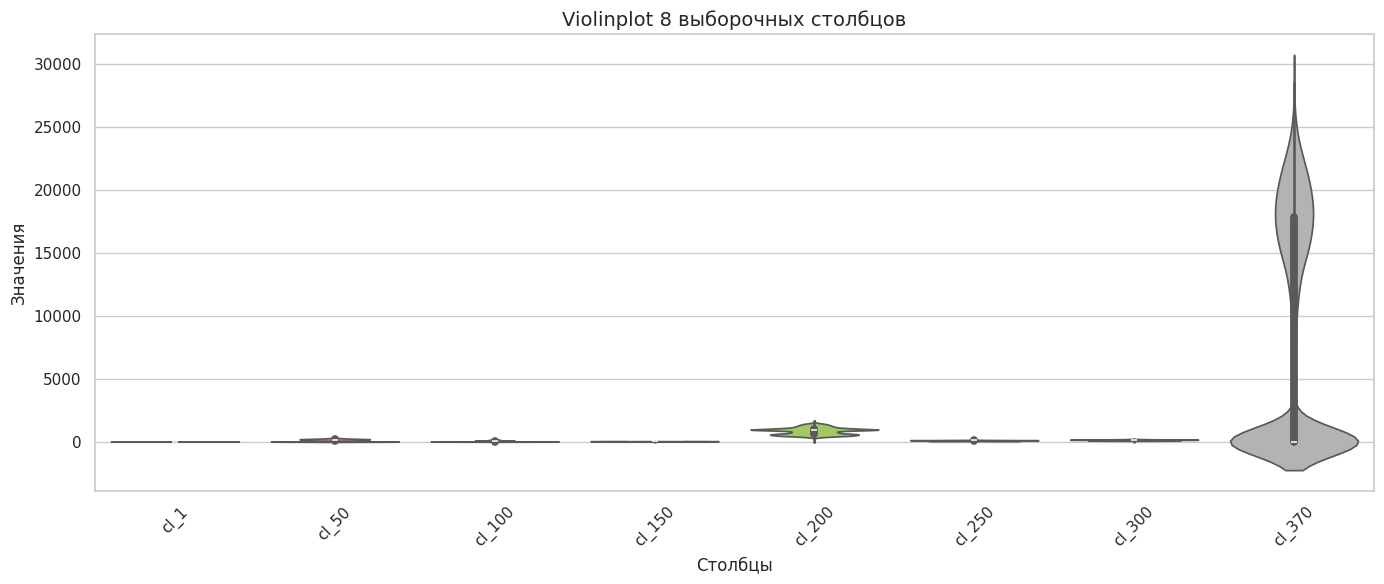

In [ ]:
# выберем случайных клиентов
sample_columns = ['cl_1', 'cl_50', 'cl_100', 'cl_150', 'cl_200', 'cl_250', 'cl_300', 'cl_370']

# создаём melted DataFrame только для выбранных столбцов
data_h_sample = data_h[sample_columns].melt(var_name='column', value_name='value')

plt.figure(figsize=(14, 6))
sns.violinplot(data=data_h_sample, x='column', y='value', palette='Set2')
plt.title(f'Violinplot {len(sample_columns)} выборочных столбцов', fontsize=14)
plt.xlabel('Столбцы', fontsize=12)
plt.ylabel('Значения', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

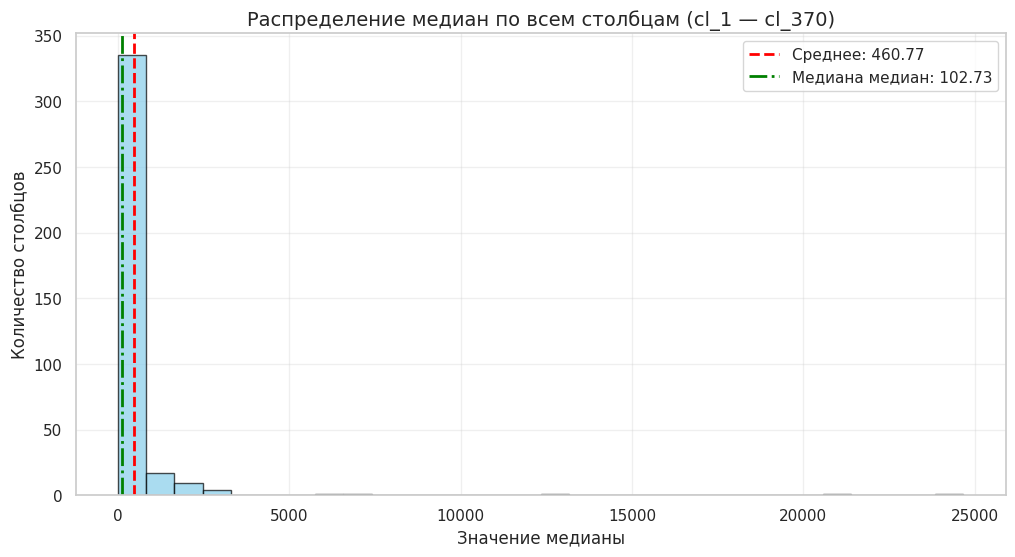

In [ ]:
medians = data_h.median()

plt.figure(figsize=(12, 6))
plt.hist(medians, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(medians.mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {medians.mean():.2f}')
plt.axvline(medians.median(), color='green', linestyle='-.', linewidth=2, label=f'Медиана медиан: {medians.median():.2f}')

plt.title('Распределение медиан по всем столбцам (cl_1 — cl_370)', fontsize=14)
plt.xlabel('Значение медианы', fontsize=12)
plt.ylabel('Количество столбцов', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Вывод

- Большая часть клиентов - небольшие потребители (домохозяйства), но есть несколько очень крупных потребителей (возможно промышленные объекты), которые делают распределение медианного потребления сильно скошенным вправо, т.е. для линейных моделей обязатльно необходимо применять масштабирование.

# Преобразуем датасет по клиентам в датасет по суммарному потреблению

In [ ]:
s_sum = data_h.sum(axis=1)
s_sum.rename('total_cons', inplace=True)
df_sum = pd.DataFrame({'total_cons': s_sum})

# Feature engineering

In [ ]:
# добавляем признаки с годом, месяцем, днём недели и часом, и флаг является ли день выходным
df_sum['hour'] = df_sum.index.hour
df_sum['year'] = df_sum.index.year
df_sum['month'] = df_sum.index.month
df_sum['day_of_week'] = df_sum.index.dayofweek
df_sum['is_weekend'] = (df_sum['day_of_week'] >= 5).astype(int)

# лаги (историческое потребление), ключевые для прогноза, т.к. предполагаю сильную автокорреляцию
for lag in [1, 2, 3, 6, 12, 24]:
    df_sum[f'lag_{lag}'] = df_sum['total_cons'].shift(lag)

df_sum['rolling_mean_24'] = df_sum['total_cons'].shift(1).rolling(window=24).mean()  # сутки
df_sum['rolling_mean_168'] = df_sum['total_cons'].shift(1).rolling(window=168).mean()  # неделя

# тренд (скользящее среднее за месяц) по годам за 720 часов = 30 дней
df_sum['rolling_avg'] = df_sum['total_cons'].shift(1).rolling(window=720, min_periods=1).mean()

# разность с лагами
df_sum['diff_1'] = df_sum['total_cons'].diff(1)

# удаление NaN от лаговых и средних признаков
df_sum.dropna(inplace=True)

In [ ]:
df_sum.head()

,total_cons,hour,year,month,day_of_week,is_weekend,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,rolling_mean_24,rolling_mean_168,rolling_avg,diff_1
datetime,,,,,,,,,,,,,,,,
2011-01-08 00:00:00,86403.301624,0,2011,1,5,1,111609.594412,130176.983542,141034.492592,151169.465609,140446.717108,85716.807571,119987.091633,112123.428059,112123.428059,-25206.292787
2011-01-08 01:00:00,72534.984171,1,2011,1,5,1,86403.301624,111609.594412,130176.983542,148836.577833,141635.560276,73297.911807,120015.695552,112329.611000,111971.237962,-13868.317453
2011-01-08 02:00:00,69325.030607,2,2011,1,5,1,72534.984171,86403.301624,111609.594412,144995.262531,140189.129706,70543.526944,119983.906900,112366.458360,111739.259998,-3209.953564
2011-01-08 03:00:00,68554.184257,3,2011,1,5,1,69325.030607,72534.984171,86403.301624,141034.492592,142817.430582,70242.037536,119933.136219,112386.362977,111491.223569,-770.846350
2011-01-08 04:00:00,69033.522311,4,2011,1,5,1,68554.184257,69325.030607,72534.984171,130176.983542,145260.850996,68884.017033,119862.809000,112398.134708,111241.589620,479.338054


# Графики распределений

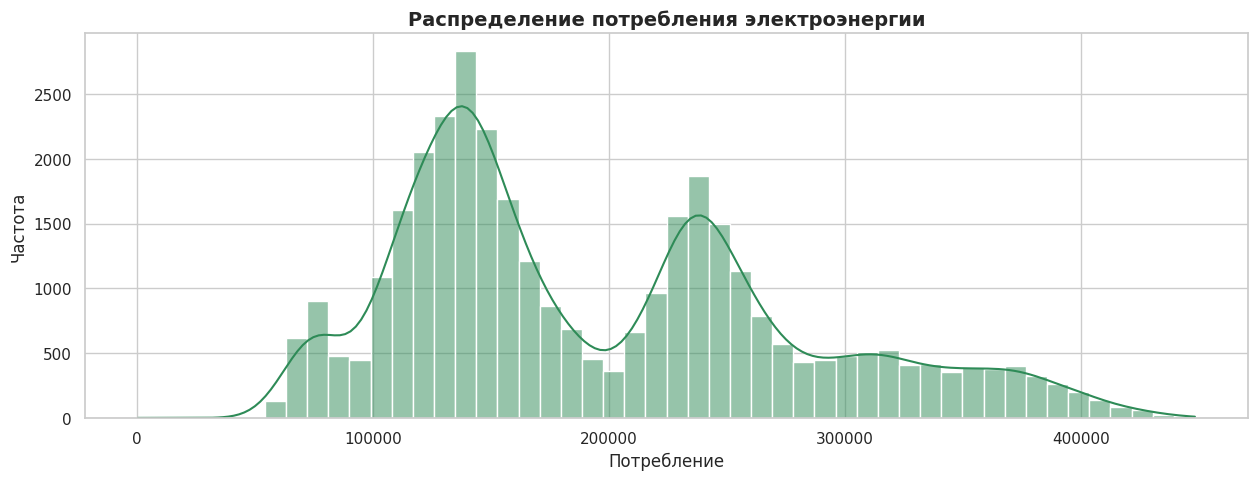

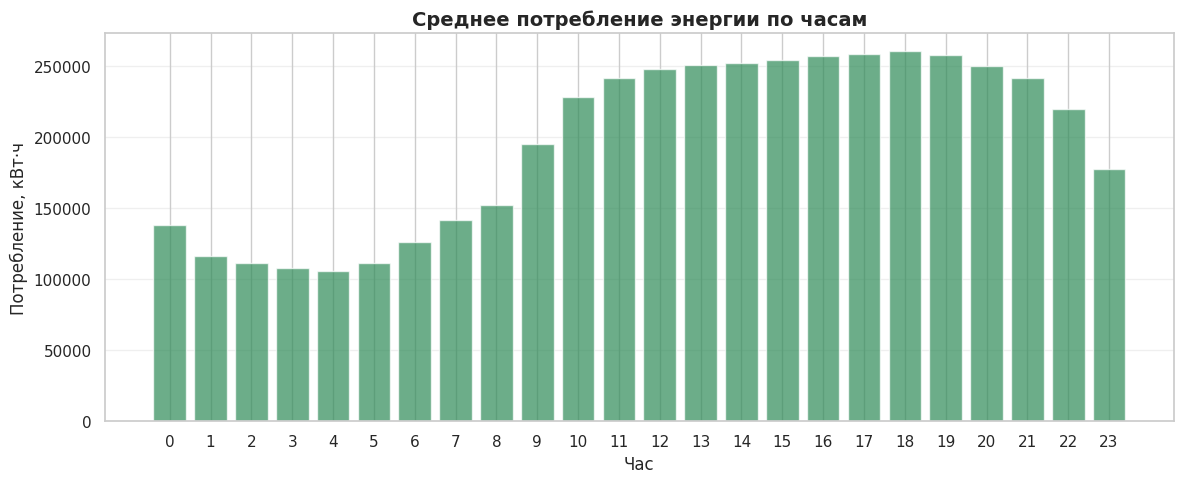

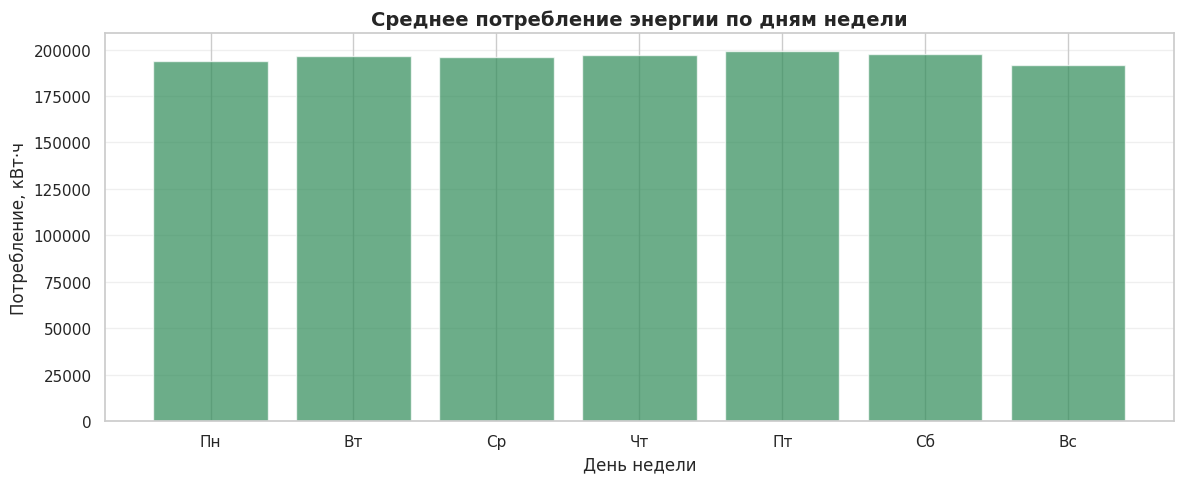

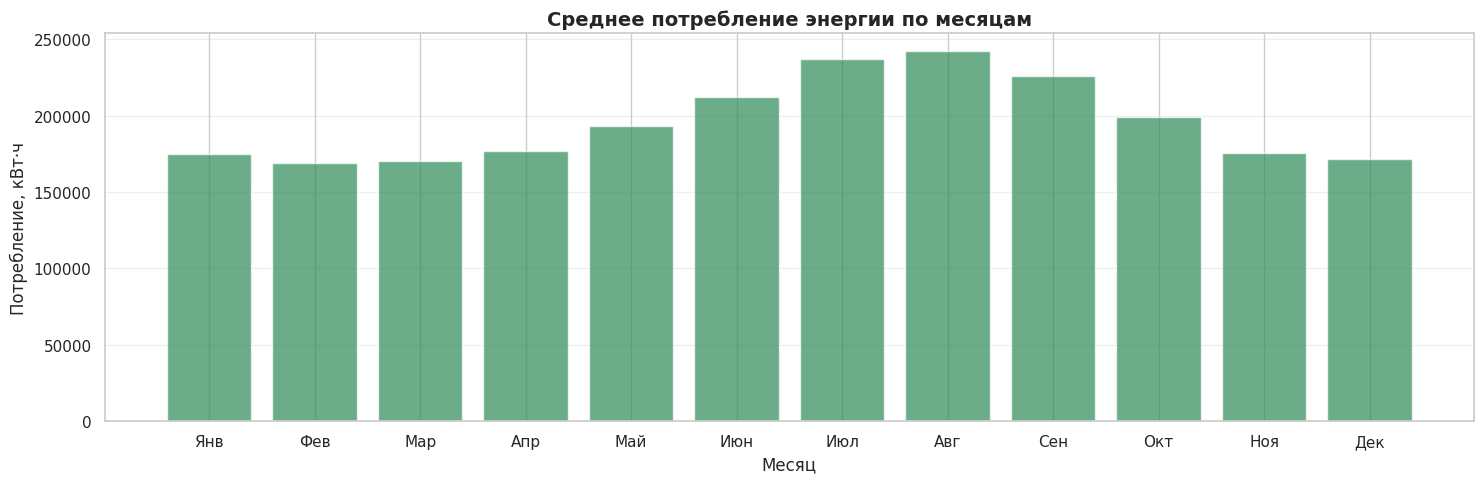

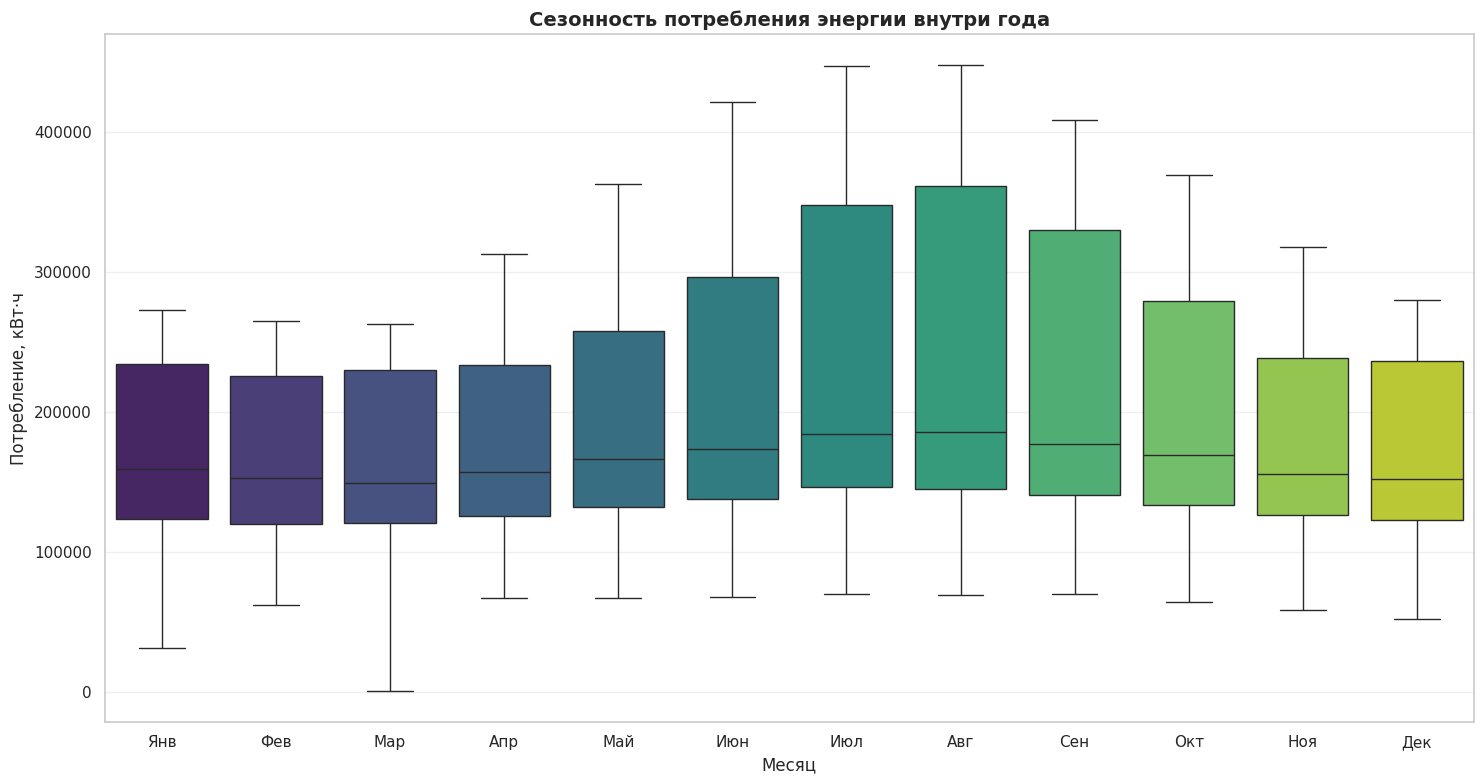

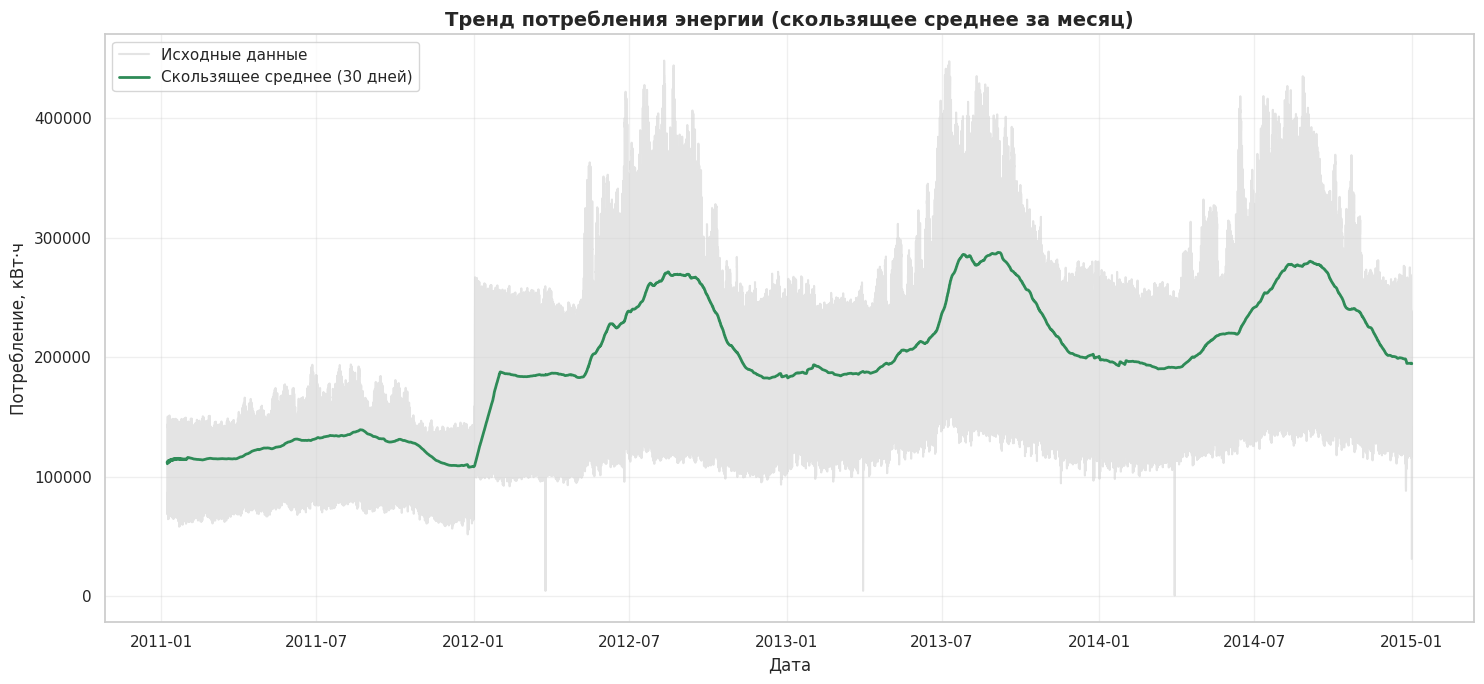

In [ ]:
sns.set_theme(style="whitegrid")

# распределение количества заказов
plt.figure(figsize=(15, 5))
sns.histplot(df_sum['total_cons'], bins=50, kde=True, color='seagreen')
plt.title('Распределение потребления электроэнергии', fontsize=14, fontweight='bold')
plt.xlabel('Потребление')
plt.ylabel('Частота')
plt.show()

# распределение потребления по часам
hourly_avg = df_sum.groupby('hour')['total_cons'].mean() # группируем по дням часам и считаем среднее потребление
plt.figure(figsize=(12, 5))
plt.bar(hourly_avg.index, hourly_avg.values, color='seagreen', alpha=0.7)
plt.title('Среднее потребление энергии по часам', fontsize=14, fontweight='bold')
plt.xlabel('Час', fontsize=12)
plt.ylabel('Потребление, кВт·ч', fontsize=12)
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# распределение потребления по дням недели
daily_avg = df_sum.groupby('day_of_week')['total_cons'].mean() # группируем по дням недели и считаем среднее потребление
days_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
plt.figure(figsize=(12, 5))
plt.bar(daily_avg.index, daily_avg.values, color='seagreen', alpha=0.7)
plt.title('Среднее потребление энергии по дням недели', fontsize=14, fontweight='bold')
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Потребление, кВт·ч', fontsize=12)
plt.xticks(range(7), days_names)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# распределение потребления по месяцам
monthly_avg = df_sum.groupby('month')['total_cons'].mean() # группируем по месяцам и считаем среднее потребление

plt.figure(figsize=(15, 5))
plt.bar(monthly_avg.index, monthly_avg.values, color='seagreen', alpha=0.7)
plt.title('Среднее потребление энергии по месяцам', fontsize=14, fontweight='bold')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Потребление, кВт·ч', fontsize=12)
plt.xticks(range(1, 13), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                            'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# сезонность потребления энергии внутри года
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_sum, x='month', y='total_cons', palette='viridis')
plt.title('Сезонность потребления энергии внутри года', fontsize=14, fontweight='bold')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Потребление, кВт·ч', fontsize=12)
plt.xticks(range(0, 12), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                         'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 7))
plt.plot(df_sum.index, df_sum['total_cons'], label='Исходные данные', alpha=0.6, color='lightgray')
plt.plot(df_sum.index, df_sum['rolling_avg'], label='Скользящее среднее (30 дней)', color='seagreen', linewidth=2)
plt.title('Тренд потребления энергии (скользящее среднее за месяц)', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Потребление, кВт·ч', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Вывод

**По графикам распределений видны:**
- 4 основных кластера потребителей до 100 гВт/ч, от 100 до 200 гВт/ч, от 200 до 280 гВт/ч и более 300 гВт/ч;
- наличие внутрисуточной (ночью потребление меньше, днём и вечером больше) и внутригодовой (с мая потребление возрастает, с сентября убывает) сезонностей;  
- отсутствие внутринедельной сезонности (во все дни недели потребление примерно равно);
- всплеск потребления начиная с 2012 года (создание клиентов, для которых ранее потребление считалось нулевым, о чём говорилось в описании);
- небольшой восходящий тренд с 2012 по 2015 год (увеличение потребления).

# Анализ корреляций

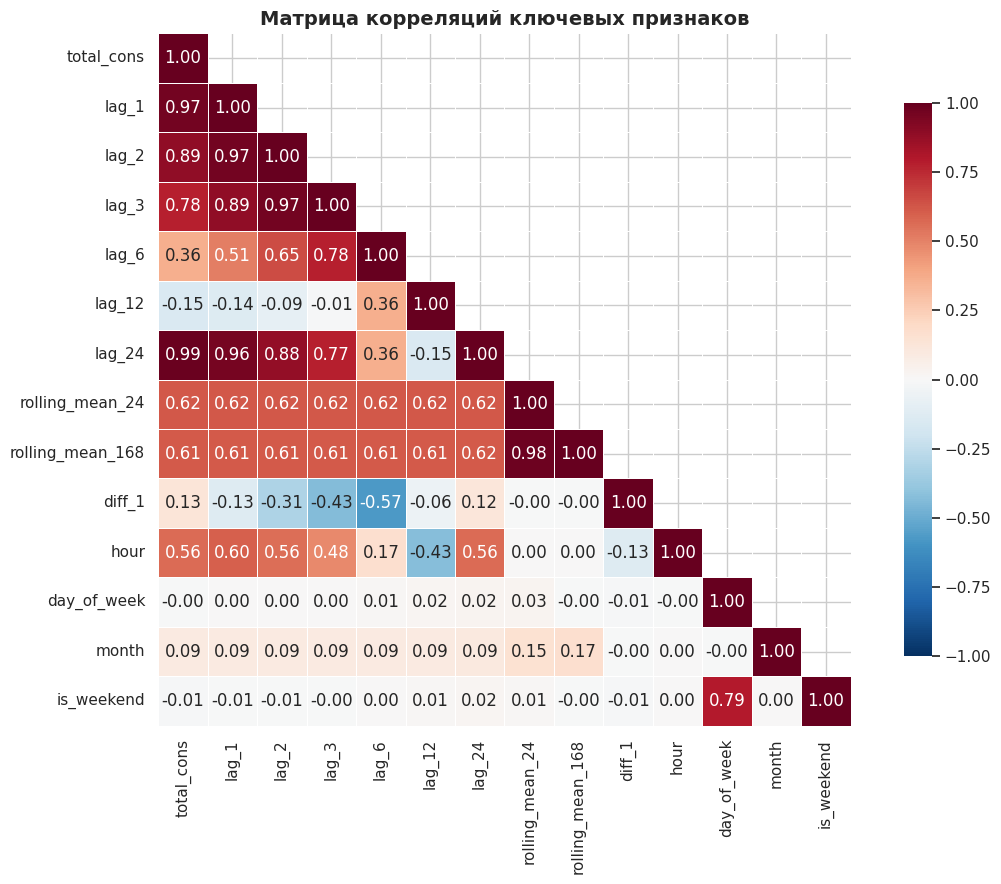

In [ ]:
corr_features = [
    'total_cons', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24',
    'rolling_mean_24', 'rolling_mean_168',
    'diff_1', 'hour', 'day_of_week', 'month', 'is_weekend'
]

corr_matrix = df_sum[corr_features].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # маскируем верхний треугольник

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Матрица корреляций ключевых признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Вывод по корреляциям

**Связь с ЦП**
- Наибольшая корреляция у лаговых признаков (`lag_1`, `lag_2`, `lag_24`) и у скользящих средних. Потребление сильно автокоррелировано (значение «час назад» и «сутки назад» — лучшие предикторы).
- Календарные признаки (`hour`, `month`, `day_of_week`) имеют слабую или отсутствующую линейную корреляцию, т.к. зависимость от них **нелинейная** (суточные пики, сезонные всплески), поэтому линейные модели её не отследят, но увидят древовидные.
- `diff_1` почти не коррелирует с таргетом, но полезен для SARIMA (стационарность).

**Мультиколлинеарность.**
- Между `lag_1` и `rolling_mean_24` (а также `rolling_mean_168`) корреляция близка к 1.0. признаки дублируют друг друга.
- Для линейных моделей сильная мультиколлинеарность ухудшает стабильность коэффициентов и их интерпретацию. Для древовидных мультиколлинеарность не критична, т.к. они выберут наиболее информативный признак при разбиении.

# Анализ выбросов

Для выявления выбросов используем IQR:

Выясним:
1. Сколько выбросов в таргете и какова их доля.
2. В какие часы суток и месяцы они концентрируются.

In [ ]:
q1 = df_sum['total_cons'].quantile(0.25)
q3 = df_sum['total_cons'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
lower_bound = 0 if lower_bound < 0 else _ # нижняя граница не может быть отрицательный, ограничим
upper_bound = q3 + 1.5 * iqr

outliers_mask = (df_sum['total_cons'] < lower_bound) | (df_sum['total_cons'] > upper_bound)
outliers = df_sum[outliers_mask]

n_outliers = int(outliers_mask.sum())
share_outliers = n_outliers / len(df_sum) * 100

print(f"Q1 (25-й перцентиль): {q1:,.0f} кВт·ч")
print(f"Q3 (75-й перцентиль): {q3:,.0f} кВт·ч")
print(f"IQR:                  {iqr:,.0f} кВт·ч")
print(f"Нижняя граница:       {lower_bound:,.0f} кВт·ч")
print(f"Верхняя граница:      {upper_bound:,.0f} кВт·ч")
print(f"Количество выбросов:  {n_outliers:,} ({share_outliers:.2f}% наблюдений)")

Q1 (25-й перцентиль): 131,600 кВт·ч
Q3 (75-й перцентиль): 248,462 кВт·ч
IQR:                  116,862 кВт·ч
Нижняя граница:       0 кВт·ч
Верхняя граница:      423,755 кВт·ч
Количество выбросов:  79 (0.23% наблюдений)


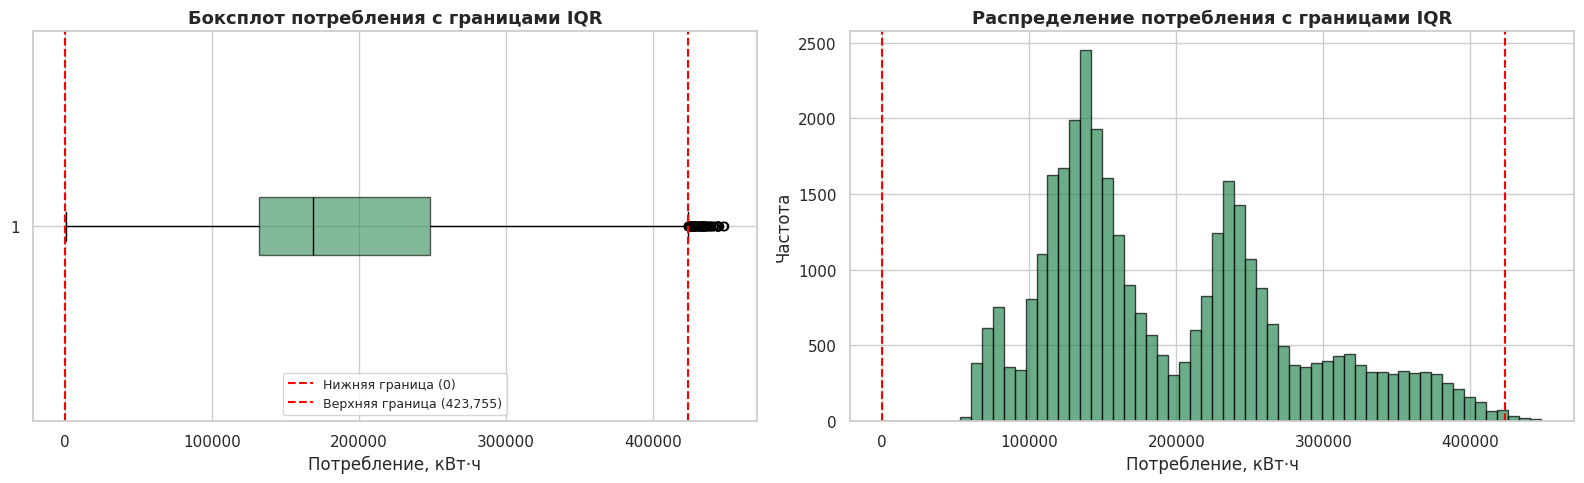

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].boxplot(
    df_sum['total_cons'], vert=False, patch_artist=True,
    boxprops=dict(facecolor='seagreen', alpha=0.6),
    medianprops=dict(color='black')
)
axes[0].axvline(lower_bound, color='red', linestyle='--',
                label=f'Нижняя граница ({lower_bound:,.0f})')
axes[0].axvline(upper_bound, color='red', linestyle='--',
                label=f'Верхняя граница ({upper_bound:,.0f})')
axes[0].set_title('Боксплот потребления с границами IQR',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Потребление, кВт·ч')
axes[0].legend(fontsize=9)



axes[1].hist(df_sum['total_cons'], bins=60,
             color='seagreen', alpha=0.7, edgecolor='black')
axes[1].axvline(lower_bound, color='red', linestyle='--')
axes[1].axvline(upper_bound, color='red', linestyle='--')
axes[1].set_title('Распределение потребления с границами IQR',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Потребление, кВт·ч')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

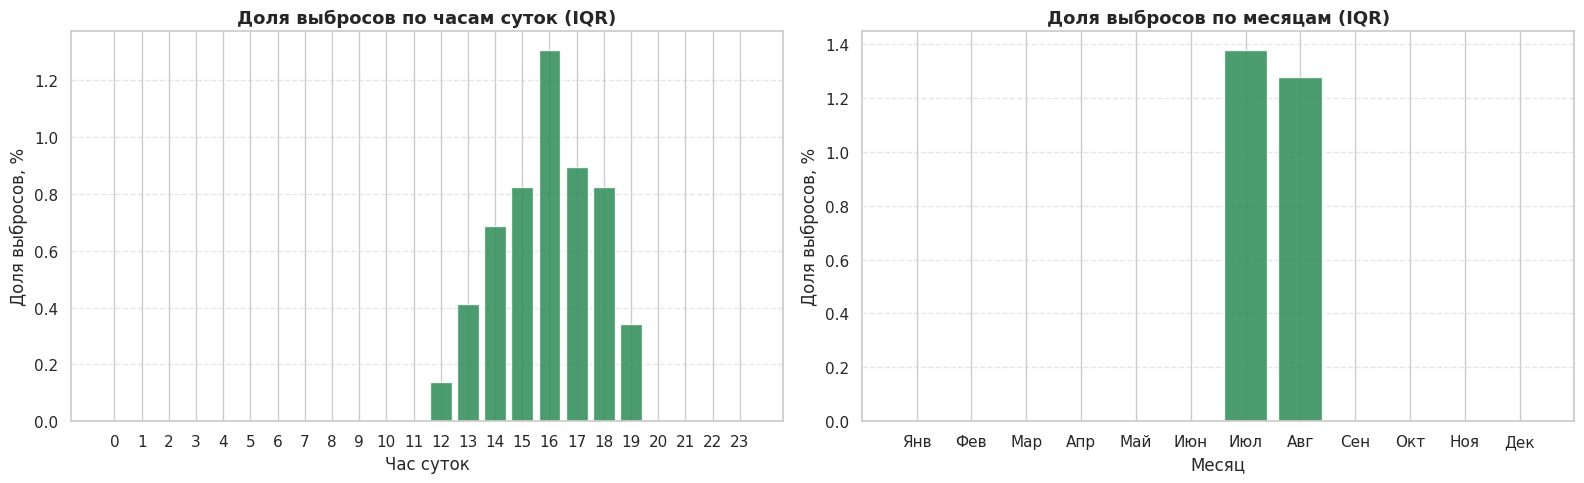

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Доля выбросов по часам суток
outliers_by_hour = outliers.groupby('hour').size().reindex(range(24), fill_value=0)
total_by_hour = df_sum.groupby('hour').size()
share_by_hour = (outliers_by_hour / total_by_hour * 100).fillna(0)

axes[0].bar(share_by_hour.index, share_by_hour.values,
            color='seagreen', alpha=0.85)
axes[0].set_title('Доля выбросов по часам суток (IQR)',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Доля выбросов, %')
axes[0].set_xticks(range(24))
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Доля выбросов по месяцам
outliers_by_month = outliers.groupby('month').size().reindex(range(1, 13), fill_value=0)
total_by_month = df_sum.groupby('month').size()
share_by_month = (outliers_by_month / total_by_month * 100).fillna(0)

month_names = ['Янв','Фев','Мар','Апр','Май','Июн',
               'Июл','Авг','Сен','Окт','Ноя','Дек']
axes[1].bar(share_by_month.index, share_by_month.values,
            color='seagreen', alpha=0.85)
axes[1].set_title('Доля выбросов по месяцам (IQR)',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Доля выбросов, %')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names, rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Вывод

По методу IQR к выбросам относится всего `0,23%` наблюдений.

**Где концентрируются.**
- По часам суток — выбросы сосредоточены в вечерние часы (16:00–18:00), когда суммарное потребление максимально (люди приходят с работы).
- По месяцам — выбросы приходятся на жаркие (июль–август) месяцы, когда активно использются системы кондиционирования.

**Удалять выбросы не будем, по следующим причинам:**
- **Бизнес-значимость.** Пиковые нагрузки — самый важный режим для энергосети (риск перегрузки, аварийных отключений), их удаление сильно исказит реальную каритину.
- **Специфика предсказаний временных рядов.** Удаление точек создаёт пробелы в хронологии, а это искажает лаги и скользящие средние. Корректнее обучать модель на полном ряде.
- **Использование методов обечпечения устойчивости моделей.** Древовидные модели в принципе малочувствительны к выбросам т.к. `используют пороговые критерии`. Для линейных моделей можно будет применить  `RobustScaler`, устойчивый к выбросам и `L2-регуляризацию`. Для SARIMA можно применить `преобразование Бокса–Кокса`, которое выровняет распределение и стабилизирует дисперсию.

# Разделение на признаки и цп

In [ ]:
X = df_sum.drop('total_cons', axis=1)
y = df_sum['total_cons']

# Метрики оценки

Будем использовать 2 метрики:
- **RMSE:** т.к. штрафует большие ошибки, а это важно для пиковых нагрузок, чтобы не допустить перегрузки сети;

- **MAPE:** т.к. легко интерпретируема в процентах для бизнеса.

In [ ]:
mape_scorer = make_scorer(mean_absolute_percentage_error, greater_is_better=False)
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mape': mape_scorer
}

# Модели

In [ ]:
full_results = []

## '0. Baseline (DummyRegressor)

In [ ]:
dummy_grid = {
    'model': Pipeline([
        ('scaler', RobustScaler()),
        ('regressor', DummyRegressor(strategy='mean'))
    ]),
    'params': {}
}

best_dummy = train_model(X, y, dummy_grid, test_size)

DummyRegressor
  RMSE (CV): 88039.8 +/- 38690.2 (CV-коэф. 43.9%) | test: 85272.7
  MAPE (CV): 0.327% +/- 0.034% | test: 35.422%
  per-fold RMSE: [np.float64(35349.5), np.float64(86220.4), np.float64(135987.8), np.float64(56791.3), np.float64(125850.0)]
  best_params: {}


In [ ]:
full_results.append({'model': 'DummyRegressor',
                     'RMSE': round(best_dummy['DummyRegressor']['RMSE'], 2),
                     'MAPE': round(best_dummy['DummyRegressor']['MAPE'], 2)})

## '1. Elastic Net

In [ ]:
eln_grid = {'model': Pipeline([
            ('scaler', RobustScaler()),
            ('regressor', ElasticNet(random_state=random_seed, max_iter=2000))
        ]),
        'params': {
            'regressor__alpha': [0.1, 1.0, 5.0, 10.0],
            'regressor__l1_ratio': [0.1, 0.5, 0.7, 0.9]
        }
    }

In [ ]:
best_eln = train_model(X, y, eln_grid, test_size)

ElasticNet
  RMSE (CV): 4501.6 +/- 1216.2 (CV-коэф. 27.0%) | test: 5097.9
  MAPE (CV): 0.018% +/- 0.003% | test: 2.042%
  per-fold RMSE: [np.float64(2195.4), np.float64(5059.4), np.float64(5044.7), np.float64(4494.1), np.float64(5714.5)]
  best_params: {'regressor__alpha': 0.1, 'regressor__l1_ratio': 0.9}


In [ ]:
full_results.append({'model': 'ElasticNet',
                     'RMSE': round(best_eln['ElasticNet']['RMSE'], 2),
                     'MAPE': round(best_eln['ElasticNet']['MAPE'], 2)})

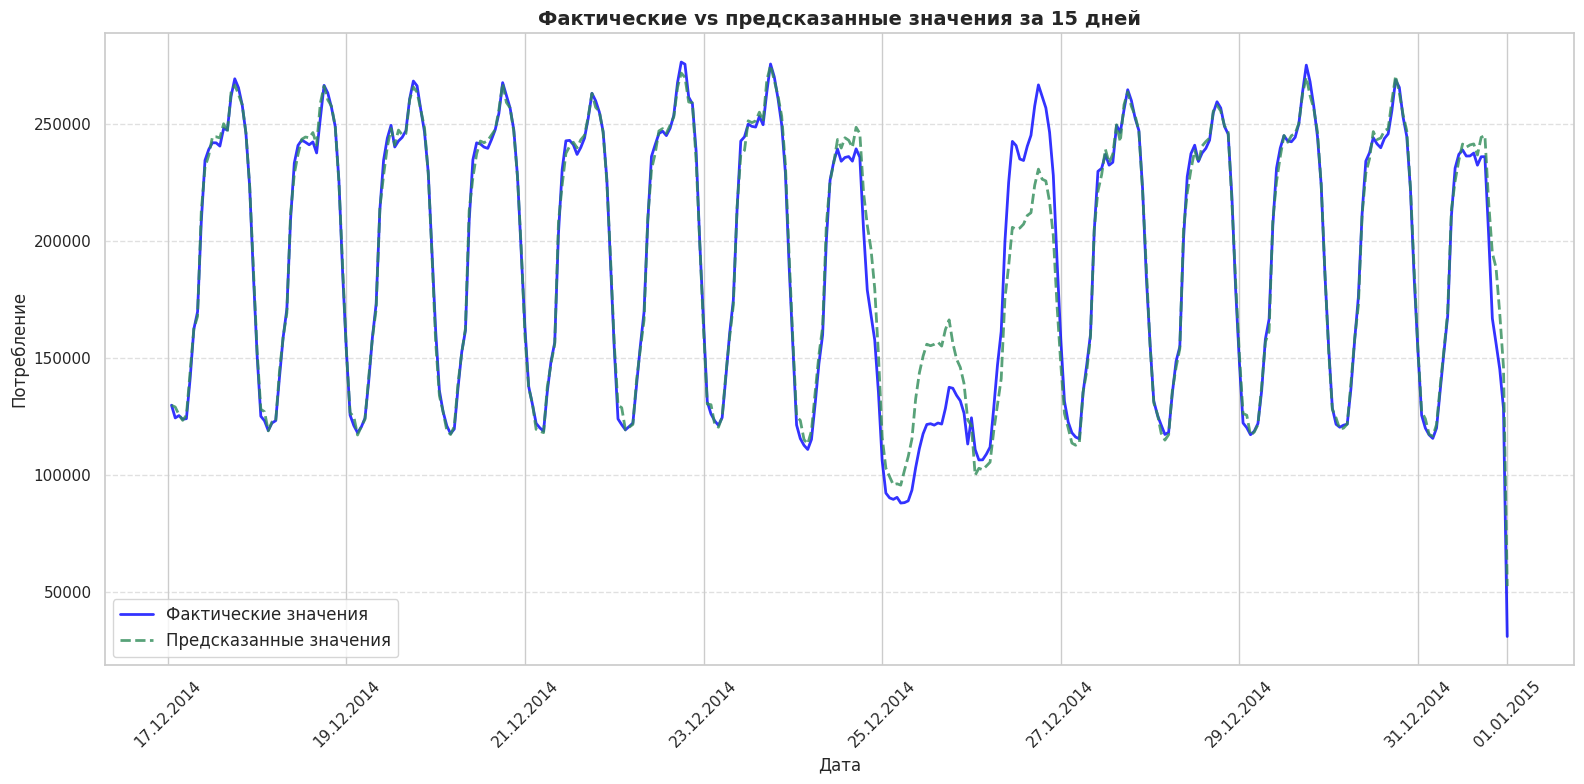

In [ ]:
comp_chart(y, best_eln['ElasticNet']['model'].predict(X), 15)

## '2. RandomForest

In [ ]:
rmf_grid = {'model': RandomForestRegressor(random_state=random_seed),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [5, 15],
            'min_samples_split': [5, 10]
        }
    }

In [ ]:
best_rmf = train_model(X, y, rmf_grid, test_size)

RandomForestRegressor
  RMSE (CV): 15053.8 +/- 14539.0 (CV-коэф. 96.6%) | test: 6094.5
  MAPE (CV): 0.046% +/- 0.046% | test: 2.500%
  per-fold RMSE: [np.float64(2370.5), np.float64(42802.6), np.float64(15639.6), np.float64(8500.1), np.float64(5956.4)]
  best_params: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}


In [ ]:
full_results.append({'model': 'RandomForestRegressor',
                     'RMSE': round(best_rmf['RandomForestRegressor']['RMSE'], 2),
                     'MAPE': round(best_rmf['RandomForestRegressor']['MAPE'], 2)})

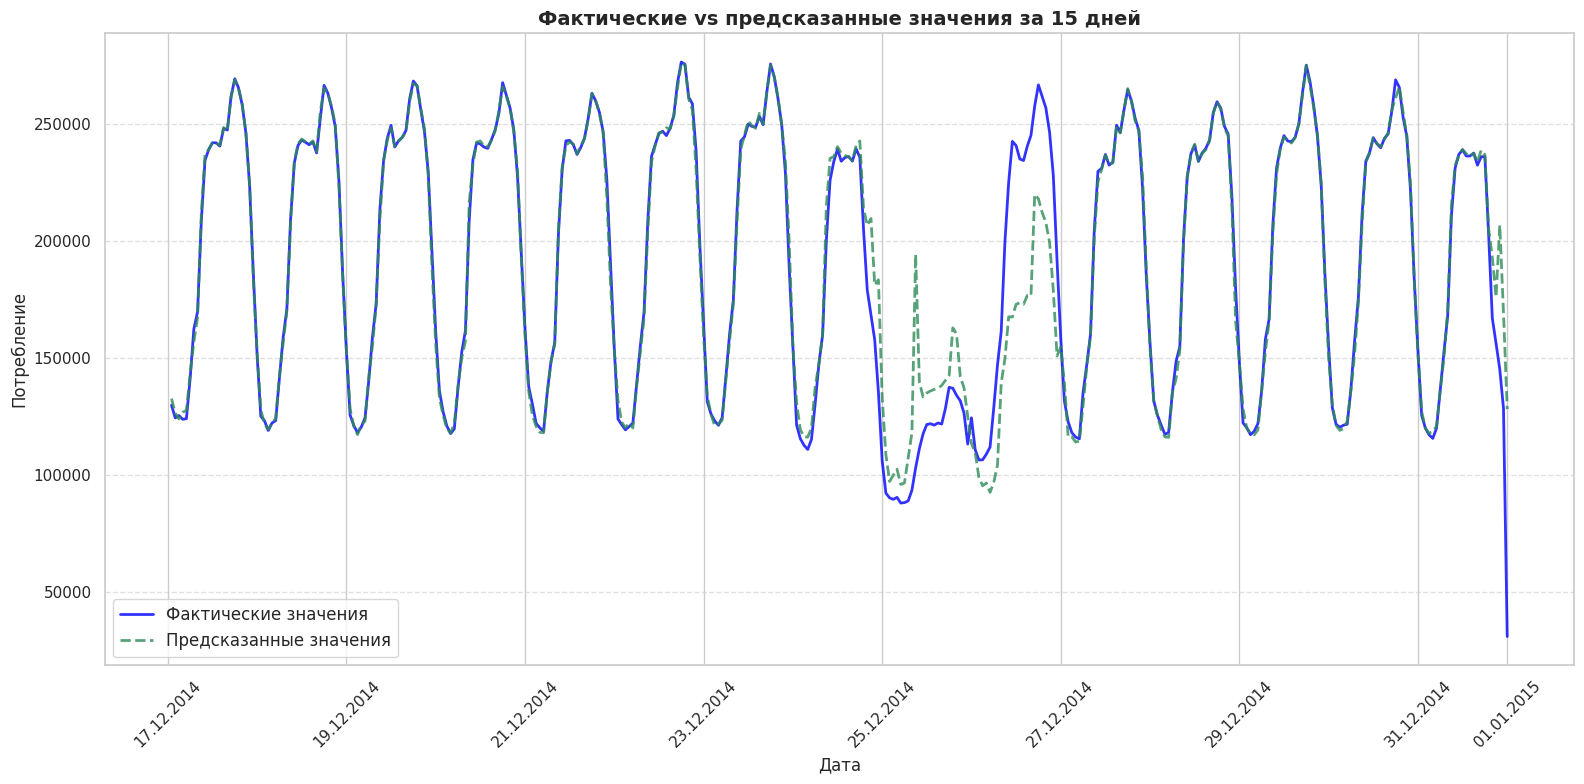

In [ ]:
comp_chart(y, best_rmf['RandomForestRegressor']['model'].predict(X), 15)

## '3. XGBoost

In [ ]:
xgb_grid = {'model': XGBRegressor(random_state=random_seed, objective='reg:squarederror'),
            'params': {
            'n_estimators': [100, 250],
            'learning_rate': [0.01, 0.1, 0.5],
            'max_depth': [4, 8]
        }
    }

In [ ]:
best_xgb = train_model(X, y, xgb_grid, test_size)

XGBRegressor
  RMSE (CV): 15322.5 +/- 14977.8 (CV-коэф. 97.8%) | test: 3876.6
  MAPE (CV): 0.045% +/- 0.047% | test: 1.566%
  per-fold RMSE: [np.float64(2030.0), np.float64(42671.4), np.float64(19963.0), np.float64(6565.0), np.float64(5383.1)]
  best_params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 250}


In [ ]:
full_results.append({'model': 'XGBRegressor',
                     'RMSE': round(best_xgb['XGBRegressor']['RMSE'], 2),
                     'MAPE': round(best_xgb['XGBRegressor']['MAPE'], 2)})

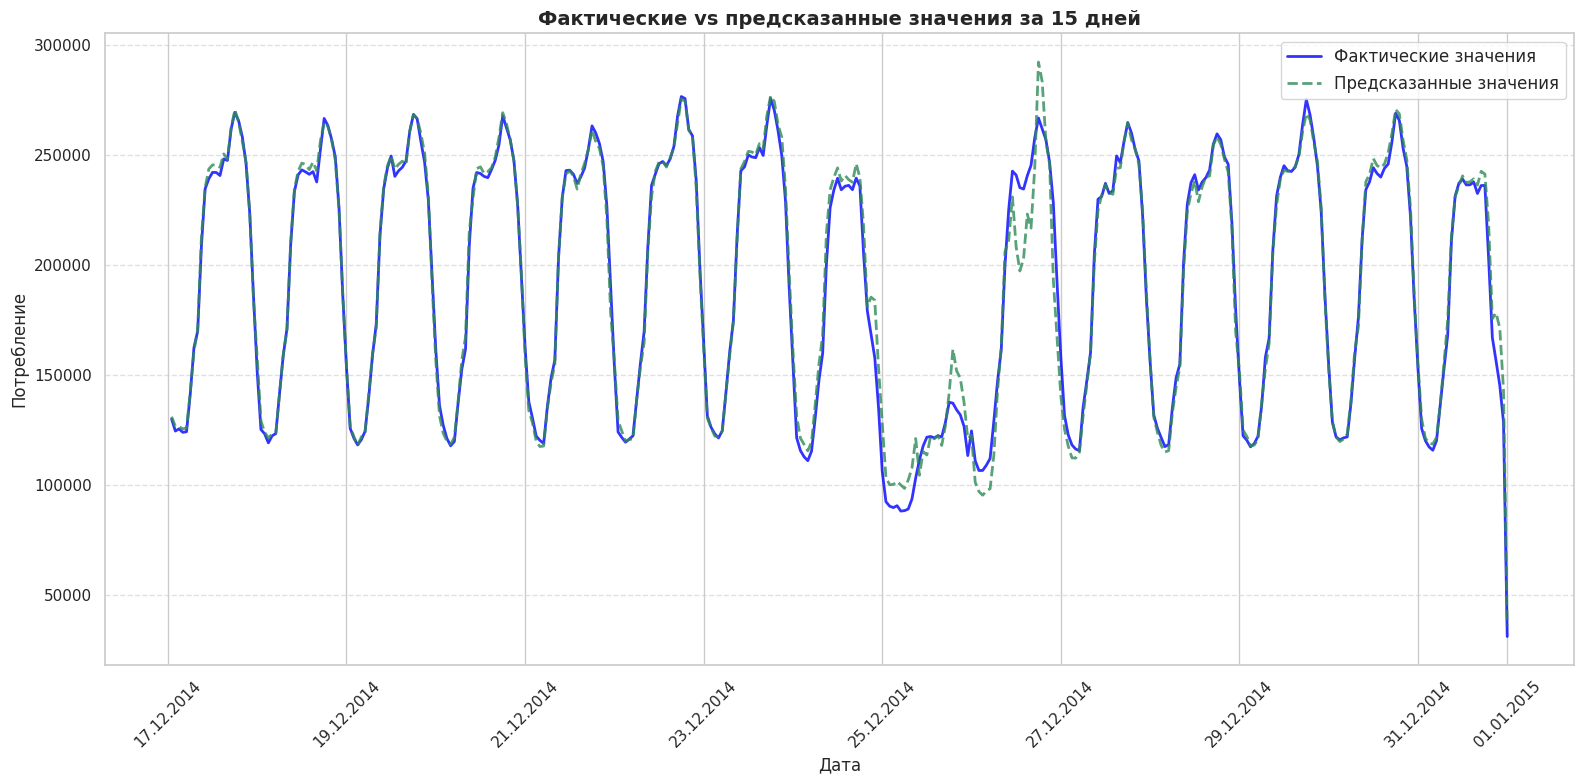

In [ ]:
comp_chart(y, best_xgb['XGBRegressor']['model'].predict(X), 15)

# Проверка на утечку данных

In [ ]:
# проверка корректности лагов: корреляция lag_k должна быть высокой,
# но не идеальной если ~0.999 — возможна утечка цп.
lag_cols = [c for c in X.columns if c.startswith('lag_')]
leak_report = (
    df_sum[['total_cons'] + lag_cols]
    .corr()['total_cons']
    .drop('total_cons')
    .sort_values(ascending=False)
)
display(leak_report)

# скользящие средние должны коррелировать с цп, но ниже lag_1
print("Проверка: корреляция rolling_mean_24 vs lag_1:")
print(df_sum[['total_cons','rolling_mean_24','lag_1']].corr()['total_cons'])

,total_cons
lag_24,0.989542
lag_1,0.968022
lag_2,0.889696
lag_3,0.780555
lag_6,0.364341
lag_12,-0.151948


Проверка: корреляция rolling_mean_24 vs lag_1:
total_cons         1.000000
rolling_mean_24    0.621306
lag_1              0.968022
Name: total_cons, dtype: float64


In [ ]:
split = int(len(X) * (1 - test_size))
assert X.index.is_monotonic_increasing, "Нарушена хронология!"
# Проверка, что тест позже трейна
assert X.index[split] > X.index[split-1]
print("OK: разбиение хронологическое, утечек по индексам нет.")

OK: разбиение хронологическое, утечек по индексам нет.


In [ ]:
# сдвиг цп на 1 назад не должен резко улучшать модель
y_shift = y.shift(1).iloc[split:]
y_shift = y_shift.dropna()
pred_shift = best_xgb['XGBRegressor']['model'].predict(X.loc[y_shift.index])
shifted_RMSE = np.sqrt(mean_squared_error(y_shift, pred_shift))
normal_RMSE = best_xgb['XGBRegressor']['RMSE']
print(f"RMSE на сдвинутой цели: {shifted_RMSE:.2f}, что в {shifted_RMSE/normal_RMSE:.1f} больше нормального")

RMSE на сдвинутой цели: 23006.19, что в 5.9 больше нормального


## Вывод

- Корреляции лагов с целевой переменной. Максимальная корреляция — lag_24 = 0.99 и lag_1 = 0.97. Значения высокие (ряд сильно автокоррелирован), но не идеальные: даже у сильнейшего признака corr < 0.999, а с увеличением лага корреляция плавно падает (0.89 → 0.78 → 0.36 → −0.15 для lag_12). Такой монотонный спад соответствует физической природе данных: суточная сезонность (lag_24) сильнее часовой (lag_1). Если бы в лагах был сдвиг в будущее, мы бы видели аномальный «всплеск» на каком-то одном лаге.

- Скользящее среднее (rolling_mean_24). Корреляция с target всего 0.62 — значительно ниже, чем у lag_1 (0.97). Если бы в окно попадало текущее значение цп, корреляция была бы ≈ 1.0. Значение 0.62 подтверждает, что окно строго ограничено прошлым.

- Тесты процесса разбиения. assert-проверки пройдены: total_cons отсутствует среди признаков, индекс монотонно возрастает, тест хронологически позже трейна. Масштабирование (RobustScaler) находится внутри Pipeline и обучается только на train-фолде.

- Сдвиговый тест. При подмене целевой переменной на «сдвинутую на 1 час» RMSE теста вырос в ~6 раз. При наличии утечки RMSE при сдвинутой цели остался бы низким, потому что «утечка» сама по себе является целью.

**Итог:** признаки-лаги и скользящие средние формируются только из прошлого, скейлер обучается только на train, разбиение хронологическое, сдвиговый тест подтверждает, что модель не «подглядывает» вперёд. Утечка данных отсутствует.

# Анализ стандартных отклонений на CV

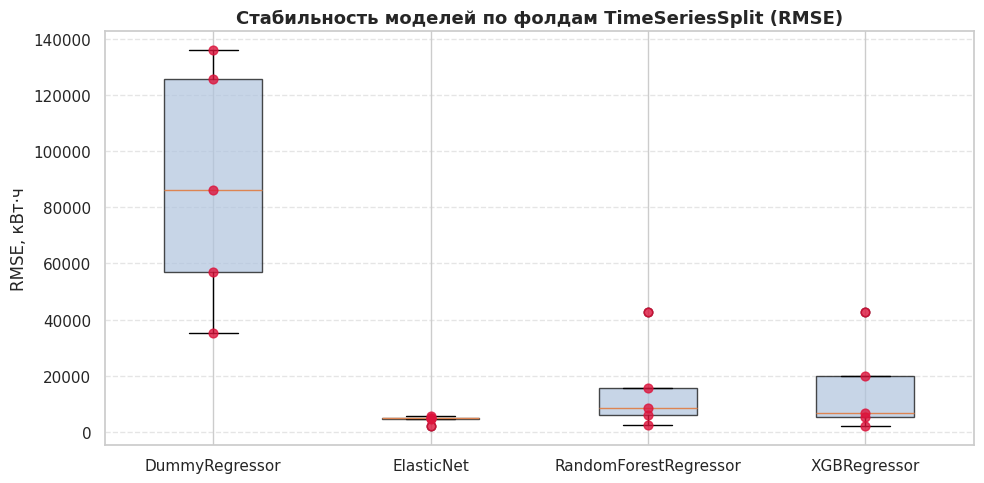

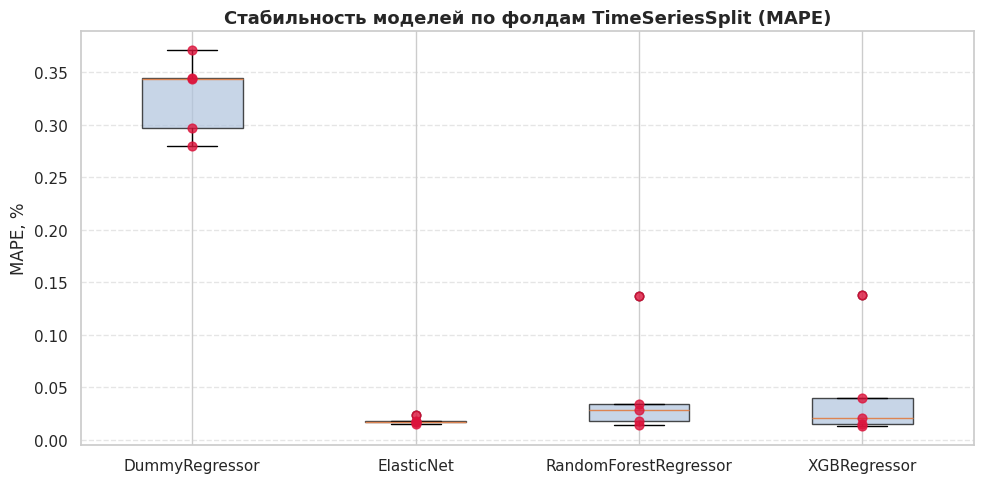

,model,CV RMSE mean,CV RMSE std,CV-коэф,Test RMSE,"Test MAPE, %"
3,XGBRegressor,15322.489,14977.790,0.978,3876.603,1.566
1,ElasticNet,4501.599,1216.217,0.270,5097.919,2.042
2,RandomForestRegressor,15053.829,14539.024,0.966,6094.547,2.500
0,DummyRegressor,88039.822,38690.232,0.439,85272.727,35.422


In [ ]:
all_models = {**best_dummy, **best_eln, **best_rmf, **best_xgb}

plot_cv_stability(all_models, metric='cv_fold_rmse',
                  title='Стабильность моделей по фолдам TimeSeriesSplit (RMSE)',
                  ylabel = 'RMSE, кВт·ч')
plot_cv_stability(all_models, metric='cv_fold_mape',
                  title='Стабильность моделей по фолдам TimeSeriesSplit (MAPE)',
                  ylabel = 'MAPE, %')

# сводная таблица mean ± std

summary = pd.DataFrame([
    {'model':       name,
     'CV RMSE mean': r['cv_mean_rmse'],
     'CV RMSE std':  r['cv_std_rmse'],
     'CV-коэф':      r['cv_coef_rmse'],
     'Test RMSE':    r['RMSE'],
     'Test MAPE, %': r['MAPE']}
    for name, r in all_models.items()
]).sort_values('Test RMSE')
display(summary.round(3))

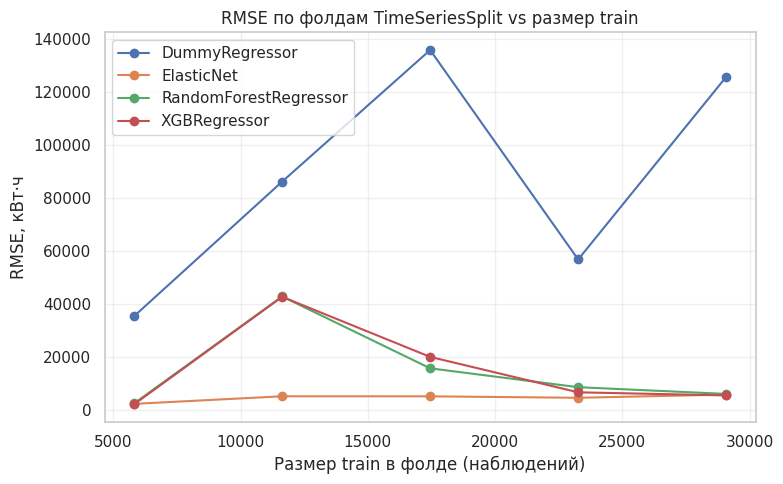

In [ ]:
plt.figure(figsize=(8, 5))
for name, r in all_models.items():
    if 'cv_fold_rmse' not in r: continue
    plt.plot(fold_sizes, r['cv_fold_rmse'], marker='o', label=name)
plt.xlabel('Размер train в фолде (наблюдений)')
plt.ylabel('RMSE, кВт·ч')
plt.title('RMSE по фолдам TimeSeriesSplit vs размер train')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Вывод
- Высокий ≈ 1 коэффициент вариации у XGBoost/RandomForest следствие TimeSeriesSplit.
На boxplot это видно по короткому IQR при одном дальнем выбросе и медиане у нижней границы ящика: разброс создаёт один фолд с маленьким количеством объектов.

- При разбиении по фолдам RMSE монотонно убывает вместе с ростом размера train выборки, а это значит что происходит недообучение на малом фолде, а не нестабильность.

- test RMSE в ~4 раза лучше CV-mean, что исключает систематическую нестабильность: полный train даёт лучший результат.

- У ElasticNet коэффициент вариации 0.27, потому что у линейной модели небольшой фолд не так сильно портит качество.

**Итог:**
Все модели кроме базовой стабильны.

# Итоговые результаты моделей

In [ ]:
full_results_df = pd.DataFrame(full_results).set_index('model')
full_results_df

,RMSE,MAPE
model,,
DummyRegressor,85272.73,35.42
ElasticNet,5097.92,2.04
RandomForestRegressor,6094.55,2.50
XGBRegressor,3876.60,1.57


# Выводы и ограничения модели

**Результаты моделей:**

- Лучшее качество по обеим метрикам показывает `XGBoost`: **RMSE = 3877** и **MAPE = 1,57 %**.
- `ElasticNet` проще интерпретировать, и быстрее работает, но показывает несколько худший результат чем `XGBoost`.

- У всех моделей train RMSE значительно ниже test (норма для временных рядов с сильной автокорреляцией), но у XGBoost разность не больше, чем у RF; относительный прирост на test не деградирует.

**Итого:** `XGBoost` — лучший выбор для данной задачи с точки зрения точности.

**Ограничения модели:**

- Модель обучена на историческом потреблении до конца 2014 и на резкий сдвиг структуры клиентов (появление/исчезновение крупных потребителей) не рассчитана.
- Модель не учитывает внешние факторы (погоду, праздники, экономические кризисы).
- Модель зависит от качества исторических данных и не работает в условиях резких изменений бизнеса (например, пандемия).
- Нет информации об отключениях и авариях → аномальные нули в данных могут ухудшать лаги.
- Горизонт: не более 24 ч, при прогнозе на >24 ч ошибки лагов накапливаются.
- Важность XGBoost показывает статистическую, а не причинную связь.
- Модель не различает новых клиентов; новых потребителей надо явно добавлять в фичи или переобучать.

**Ограничения использования**
- Модель не предназначена для прямого управления балансом сети без контроля.
- При обнаружении дрейфа требуется отдельное дообучение.

# Важность признаков

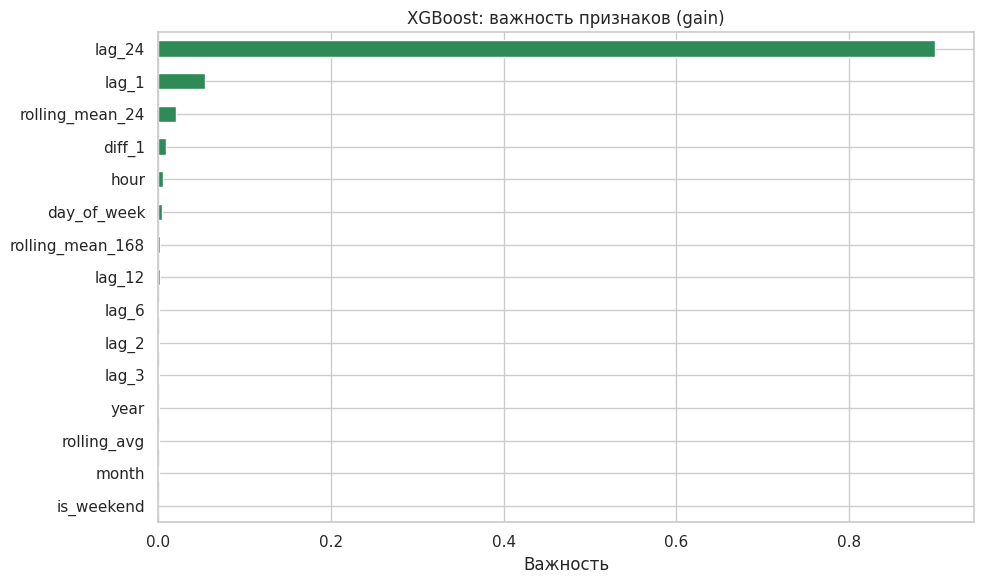

In [ ]:
xgb_model = best_xgb['XGBRegressor']['model']
xgb_imp = pd.Series(
    xgb_model.feature_importances_,
    index=xgb_model.feature_names_in_
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
xgb_imp.tail(15).plot(kind='barh', color='seagreen')
plt.title('XGBoost: важность признаков (gain)')
plt.xlabel('Важность')
plt.tight_layout(); plt.show()

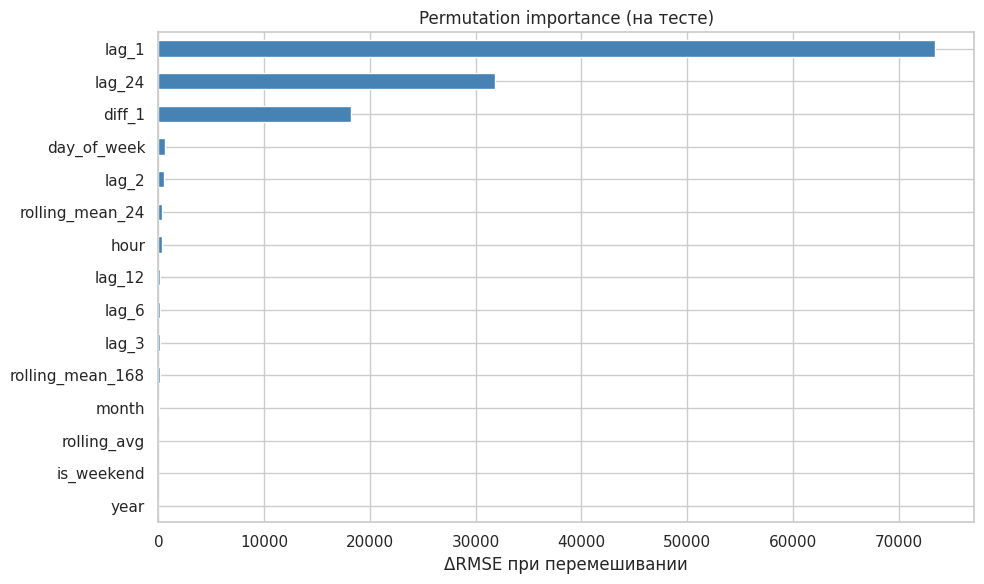

In [ ]:
perm = permutation_importance(
    xgb_model, X.iloc[split:], y.iloc[split:],
    n_repeats=5, random_state=random_seed, scoring='neg_root_mean_squared_error'
)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
perm_imp.tail(15).plot(kind='barh', color='steelblue')
plt.title('Permutation importance (на тесте)')
plt.xlabel('ΔRMSE при перемешивании')
plt.tight_layout(); plt.show()

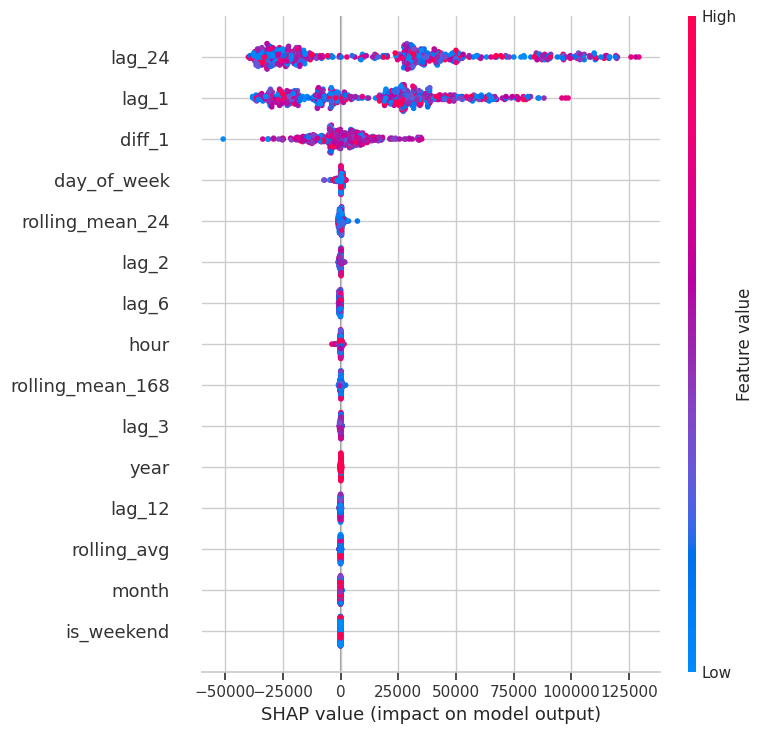

In [ ]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X.iloc[split:].sample(min(500, len(y) - split)))
shap.summary_plot(shap_values, X.iloc[split:].sample(min(500, len(y) - split)))

## Вывод

Все три метода оценки важности выделяют три ключевых предиктора — lag_24, lag_1 и diff_1; остальные признаки (календарные, скользящие средние, лаги больших порядков) вносят пренебрежимо малый вклад.

**1. Встроенная важность XGBoost (gain)**

Абсолютным лидером является lag_24 (≈ 0.96), за ним с большим отрывом следуют lag_1 и diff_1; календарные признаки (hour, day_of_week) и скользящие средние почти нулевые. gain отражает, как часто и насколько полезно признак использовался при построении деревьев. lag_24 даёт самую чистую суточную сезонность (тот же час вчера), поэтому деревья активно на него разбиваются.

**2. Permutation importance (на тесте)**

Картина меняется местами: lag_1 выходит на первое место (≈ 88 000 ΔRMSE), затем diff_1 (≈ 27 000) и только потом lag_24 (≈ 25 000). Это не ошибка, т.к. permutation измеряет реальное падение качества при перемешивании признака. Перемешивание lag_1 разрушает ближайший к прогнозу сигнал (потребление в предыдущий час) — отсюда максимальный ΔRMSE.

**3. SHAP**

SHAP-график подтверждает: lag_24, lag_1 и diff_1 — единственные признаки с широким разбросом значений вклада (большой «веер» точек как в положительную, так и в отрицательную сторону). У остальных признаков SHAP-значения сконцентрированы около нуля — они практически не влияют на предсказание. Разброс вклада lag_24/lag_1 означает, что при высоких и низких значениях этих лагов прогноз сильно смещается, что соответствует физическому смыслу: именно от недавнего и суточного потребления зависит текущая нагрузка.

**4. Сопоставление с EDA.**

EDA показал сильную автокорреляцию ряда и наличие суточной сезонности — доминирование lag_24 и lag_1 полностью это подтверждает. Календарные признаки (hour, month, day_of_week) имели низкую линейную корреляцию с target в EDA — и на важности они также оказались малозначимыми: их нелинейный вклад «поглощается» лагами (особенно lag_24), которые уже кодируют суточный и недельный ритм.

Признак diff_1 (разность с предыдущим часом) оказался неожиданно полезным: он позволяет модели улавливать тренд и ускорение потребления, а не только уровни. Это совпадает с выводом EDA о наличии внутрисуточного тренда и подтверждает гипотезу, заложенную при feature engineering.

**Практический вывод:**

Для упрощения модели без ощутимой потери качества можно оставить 3–5 наиболее релевантных признаков: lag_24, lag_1, diff_1, hour, day_of_week. Это сократит время обучения и размер модели в проде.

Календарные признаки и скользящие средние стоит сохранить в «полной» версии модели: на историческом тесте они малозначимы, но могут играть роль при дрифте (праздники, смена режима недели).

rolling_mean_168 не даёт прироста — либо убрать, либо заменить на более информативный признак (например, недельный lag_168 или статистику праздников).

# Дрейф данных

In [ ]:
# ks тест
drift_df = data_drift_report(X.iloc[:split], X.iloc[split:])
print(f"Дрейф более чем по {drift_df['drift'].sum()} из {len(drift_df)} признаков")
display(drift_df.head(10))

ALERT_SHARE = 0.3
share = drift_df['drift'].mean()
if share > ALERT_SHARE:
    print(f"Дрейф в {share:.0%} признаков (> {ALERT_SHARE:.0%})")

Дрейф более чем по 12 из 15 признаков


,feature,ks_stat,p_value,drift
1,year,0.836772,0.000000e+00,True
13,rolling_avg,0.617923,0.000000e+00,True
12,rolling_mean_168,0.545369,0.000000e+00,True
11,rolling_mean_24,0.503181,0.000000e+00,True
10,lag_24,0.224431,0.000000e+00,True
8,lag_6,0.224145,0.000000e+00,True
9,lag_12,0.224076,0.000000e+00,True
7,lag_3,0.223735,0.000000e+00,True
6,lag_2,0.223599,0.000000e+00,True
5,lag_1,0.223462,5.039470e-322,True


Дрейф в 80% признаков (> 30%)


In [ ]:
# сколько раз из 5 переходов признак дрифтовал
rolling_drift_report(X, n_windows=6)

,mean_ks,n_alert_windows
feature,,
year,0.597490,5
rolling_avg,0.488755,5
month,0.482016,5
rolling_mean_168,0.444635,5
rolling_mean_24,0.427785,4
lag_6,0.220840,3
lag_3,0.220806,3
lag_2,0.220771,3
lag_1,0.220737,3


## Вывод

Первичный KS-тест train-vs-test зафиксировал дрейф по 12 из 15 признаков:

- Дрейф year — train 2011–2013, test 2014 просто обозначение времени.

- Дрейф лагов (lag_1…lag_24, KS ≈ 0.22) и rolling-средних (KS ≈ 0.50–0.62) отражает реальный восходящий тренд в потреблении с 2012 и суточную/недельную сезонность — это ожидаемый сдвиг, а не дрейф данных.

- Календарные признаки (hour, day_of_week, month, is_weekend) и diff_1 — стационарны (дрейфа нет).


Алерт срабатывает только на rolling_mean_* и rolling_avg — значит, эти признаки надо переобучать/пересчитывать чаще, чем лаги. Лаги, будучи сдвинутой копией target, дрифтуют предсказуемо и в мониторинге не нуждаются в такой же частоте алертов.